# Exercice 7 : Visualisation et agrégation des logs météo


Consommer les logs HDFS et Implémentez les visualisations suivantes :
Évolution de la température au fil du temps
Évolution de la vitesse du vent
Nombre dʼalertes vent et chaleur par niveau
Code météo le plus fréquent par pays

## lire tous les fichiers HDFS

In [1]:
from hdfs import InsecureClient
import json
import pandas as pd
import matplotlib.pyplot as plt

DOSSIER_HDFS = "/hdfs-data"
client = InsecureClient("http://namenode:9870", user="root")

lignes = []
for dossier, sous_dossiers, fichiers in client.walk(DOSSIER_HDFS):
    for f in fichiers:
        chemin = dossier + "/" + f
        with client.read(chemin, encoding="utf-8") as lecteur:
            for ligne in lecteur.read().splitlines():
                if ligne.strip() != "":
                    lignes.append(json.loads(ligne))
        print("lu :", chemin)

df = pd.DataFrame(lignes)
df["event_time"] = pd.to_datetime(df["event_time"])
df = df.sort_values("event_time")

print()
print("Nombre total de messages :", len(df))
print("Période :", df["event_time"].min(), "->", df["event_time"].max())
df.head()


lu : /hdfs-data/France/Paris/alerts.json
lu : /hdfs-data/Iceland/Reykjavik/alerts.json
lu : /hdfs-data/New Zealand/Wellington/alerts.json
lu : /hdfs-data/Spain/Seville/alerts.json
lu : /hdfs-data/United Arab Emirates/Dubai/alerts.json

Nombre total de messages : 3880
Période : 2026-11-10 14:51:48.428000+00:00 -> 2026-11-10 21:30:27.360000+00:00


,event_time,city,country,temperature,windspeed,weather_code,wind_alert_level,heat_alert_level
0,2026-11-10 14:51:48.428000+00:00,Paris,France,12.4,2.13,3.0,level_0,level_0
2328,2026-11-10 14:51:48.540000+00:00,Seville,Spain,21.3,5.42,80.0,level_0,level_0
3104,2026-11-10 14:51:48.659000+00:00,Dubai,United Arab Emirates,30.2,3.00,0.0,level_0,level_1
776,2026-11-10 14:51:48.780000+00:00,Reykjavik,Iceland,6.8,6.80,0.0,level_0,level_0
1552,2026-11-10 14:51:48.888000+00:00,Wellington,New Zealand,15.4,8.54,51.0,level_0,level_0


## Évolution de la température au fil du temps


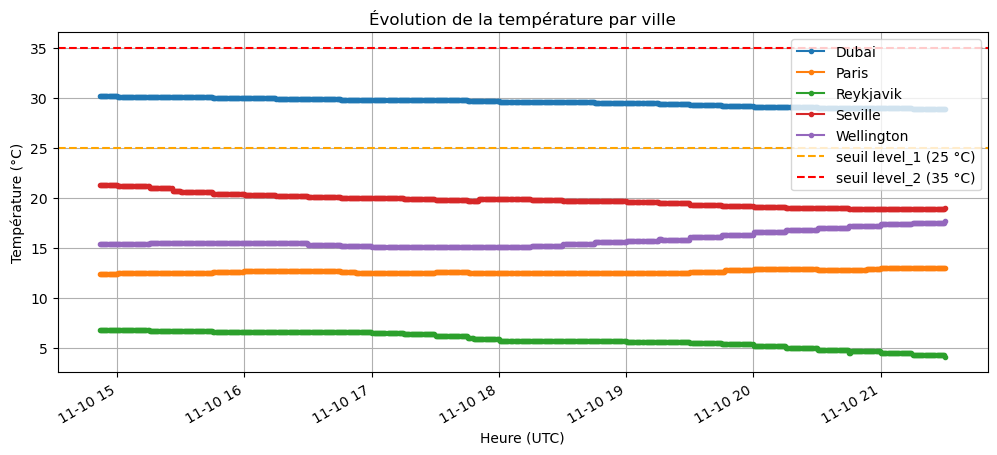

In [2]:
fig, ax = plt.subplots(figsize=(12, 5))

for ville, donnees_ville in df.groupby("city"):
    ax.plot(donnees_ville["event_time"], donnees_ville["temperature"], marker=".", label=ville)

ax.axhline(25, color="orange", linestyle="--", label="seuil level_1 (25 °C)")
ax.axhline(35, color="red", linestyle="--", label="seuil level_2 (35 °C)")

ax.set_title("Évolution de la température par ville")
ax.set_xlabel("Heure (UTC)")
ax.set_ylabel("Température (°C)")
ax.legend()
ax.grid(True)
fig.autofmt_xdate()
plt.show()


## Évolution de la vitesse du vent


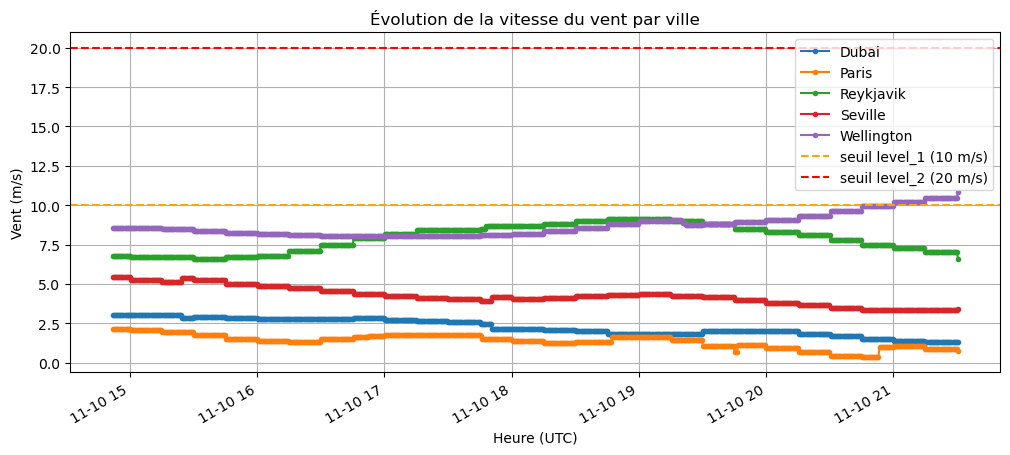

In [3]:
fig, ax = plt.subplots(figsize=(12, 5))

for ville, donnees_ville in df.groupby("city"):
    ax.plot(donnees_ville["event_time"], donnees_ville["windspeed"], marker=".", label=ville)

ax.axhline(10, color="orange", linestyle="--", label="seuil level_1 (10 m/s)")
ax.axhline(20, color="red", linestyle="--", label="seuil level_2 (20 m/s)")

ax.set_title("Évolution de la vitesse du vent par ville")
ax.set_xlabel("Heure (UTC)")
ax.set_ylabel("Vent (m/s)")
ax.legend()
ax.grid(True)
fig.autofmt_xdate()
plt.show()


##  Nombre d'alertes vent et chaleur par niveau


         vent  chaleur
level_0  3809     3096
level_1    60      773
level_2    11       11


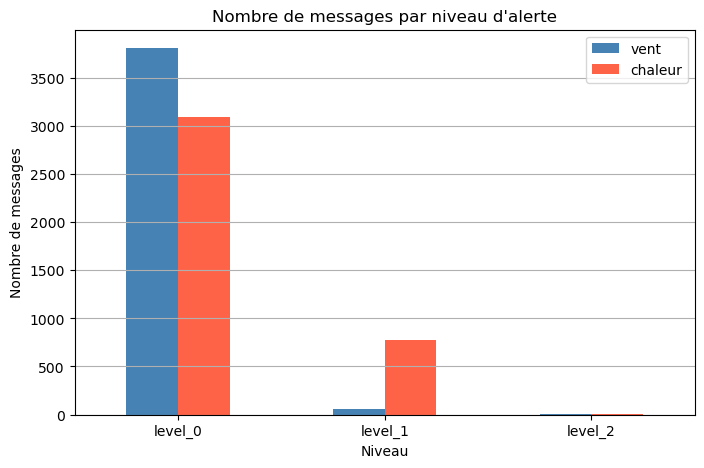

In [4]:
## `level_0` = pas d'alerte, `level_1` = alerte modérée, `level_2` = alerte forte.

niveaux = ["level_0", "level_1", "level_2"]

alertes_vent = df["wind_alert_level"].value_counts()
alertes_chaleur = df["heat_alert_level"].value_counts()

tableau_alertes = pd.DataFrame({
    "vent": alertes_vent,
    "chaleur": alertes_chaleur
})
tableau_alertes = tableau_alertes.reindex(niveaux).fillna(0).astype(int)
print(tableau_alertes)

ax = tableau_alertes.plot(kind="bar", figsize=(8, 5), color=["steelblue", "tomato"])
ax.set_title("Nombre de messages par niveau d'alerte")
ax.set_xlabel("Niveau")
ax.set_ylabel("Nombre de messages")
ax.grid(True, axis="y")
plt.xticks(rotation=0)
plt.show()


### quelles villes déclenchent les alertes

In [5]:
print("Alertes chaleur par ville :")
print(pd.crosstab(df["city"], df["heat_alert_level"]))
print()
print("Alertes vent par ville :")
print(pd.crosstab(df["city"], df["wind_alert_level"]))


Alertes chaleur par ville :
heat_alert_level  level_0  level_1  level_2
city                                       
Dubai                   0      773        3
Paris                 775        0        1
Reykjavik             773        0        3
Seville               774        0        2
Wellington            774        0        2

Alertes vent par ville :
wind_alert_level  level_0  level_1  level_2
city                                       
Dubai                 773        0        3
Paris                 775        0        1
Reykjavik             773        0        3
Seville               774        0        2
Wellington            714       60        2


## Code météo le plus fréquent par pays

                 country  weather_code  nb_messages   description
1                 France          61.0          300  Pluie faible
6                Iceland           0.0          545   Ciel dégagé
13           New Zealand           3.0          320       Couvert
15                 Spain           3.0          395       Couvert
17  United Arab Emirates           0.0          773   Ciel dégagé


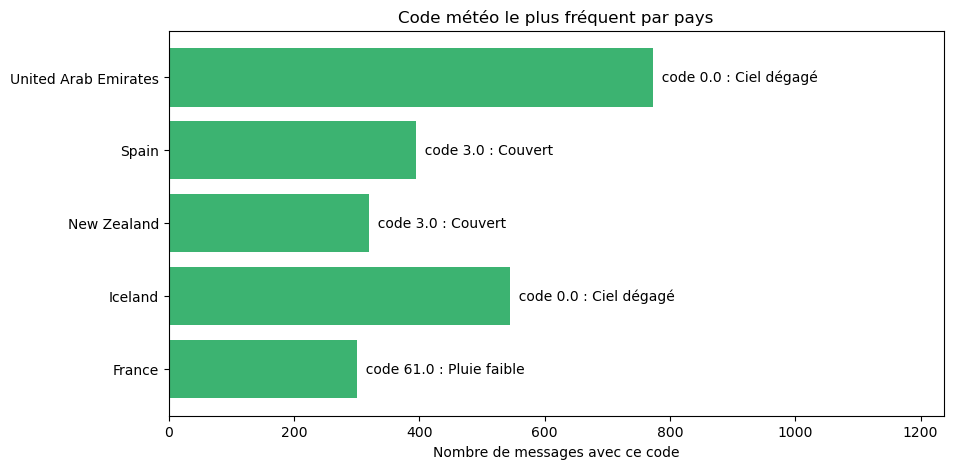

In [6]:
codes_wmo = {
    0: "Ciel dégagé", 1: "Plutôt dégagé", 2: "Partiellement nuageux", 3: "Couvert",
    45: "Brouillard", 48: "Brouillard givrant",
    51: "Bruine légère", 53: "Bruine modérée", 55: "Bruine dense",
    56: "Bruine verglaçante légère", 57: "Bruine verglaçante dense",
    61: "Pluie faible", 63: "Pluie modérée", 65: "Pluie forte",
    66: "Pluie verglaçante légère", 67: "Pluie verglaçante forte",
    71: "Neige faible", 73: "Neige modérée", 75: "Neige forte", 77: "Grains de neige",
    80: "Averses faibles", 81: "Averses modérées", 82: "Averses violentes",
    85: "Averses de neige faibles", 86: "Averses de neige fortes",
    95: "Orage", 96: "Orage avec grêle légère", 99: "Orage avec grêle forte"
}

comptage = df.groupby(["country", "weather_code"]).size().reset_index(name="nb_messages")
comptage = comptage.sort_values("nb_messages", ascending=False)
plus_frequent = comptage.drop_duplicates(subset="country").sort_values("country")

plus_frequent["description"] = plus_frequent["weather_code"].map(codes_wmo)
print(plus_frequent)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(plus_frequent["country"], plus_frequent["nb_messages"], color="mediumseagreen")
for i, ligne in enumerate(plus_frequent.itertuples()):
    ax.text(ligne.nb_messages, i, "  code " + str(ligne.weather_code) + " : " + str(ligne.description), va="center")

ax.set_title("Code météo le plus fréquent par pays")
ax.set_xlabel("Nombre de messages avec ce code")
ax.set_xlim(0, plus_frequent["nb_messages"].max() * 1.6)
plt.show()
